# Phase 2 Task 3: Dark Artifact Check

**Objective:** Scan dataset for images with dark artifacts

**Date:** 30-09-2026

## 1. Setup

In [1]:
from pathlib import Path
import sys

CWD = Path.cwd()
for i, part in enumerate(CWD.parts):
    if part == 'woodbench':
        ROOT = Path(*CWD.parts[:i+1])
        break
else:
    ROOT = CWD

sys.path.insert(0, str(ROOT))
OUTPUT_DIR = ROOT / 'artifacts/phase_2/supervisor-feedback/task_03_dark_artifact_check'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

print(f"ROOT: {ROOT}")

ROOT: /home/sakana/Code/ManifoldsTeam/woodbench


## 2. Define Detection Functions

In [2]:
def detect_dark_artifact(img, threshold=30/255, min_fraction=0.02):
    arr = np.array(img.convert('RGB')).astype(float) / 255.0
    dark_mask = arr.mean(axis=2) < threshold
    dark_fraction = dark_mask.mean()
    mean_brightness = arr.mean()
    return {
        'has_dark_artifact': dark_fraction > min_fraction,
        'dark_fraction': dark_fraction,
        'mean_brightness': mean_brightness,
    }

def analyze_image(img_path):
    try:
        img = Image.open(img_path)
        arr = np.array(img.convert('RGB')).astype(float) / 255.0
        return {
            'path': str(img_path),
            'filename': img_path.name,
            'mean': arr.mean(),
            'std': arr.std(),
            'min': arr.min(),
            'max': arr.max(),
            'dark_5pct': (arr.mean(axis=2) < 0.05).mean(),
            'dark_10pct': (arr.mean(axis=2) < 0.10).mean(),
            'very_dark': (arr.mean(axis=2) < 0.01).mean(),
        }
    except Exception as e:
        return {'path': str(img_path), 'error': str(e)}

print("Functions defined")

Functions defined


## 3. Scan Dataset

In [3]:
DATA_DIR = ROOT / "data" / "task-B-group-split"

# Collect images
all_images = []
for split in ['train', 'val', 'test']:
    split_dir = DATA_DIR / split
    if split_dir.exists():
        for species_dir in sorted(split_dir.iterdir()):
            if species_dir.is_dir():
                for img_path in species_dir.glob("*.png"):
                    all_images.append(img_path)

print(f"Total images: {len(all_images)}")

Total images: 4800


## 4. Analyze All Images

In [4]:
results = []
for img_path in tqdm(all_images, desc="Scanning"):
    stats = analyze_image(img_path)
    if 'error' not in stats:
        # Extract species
        parts = img_path.parts
        for i, p in enumerate(parts):
            if p in ['train', 'val', 'test'] and i+1 < len(parts):
                stats['species'] = parts[i+1]
                break
        results.append(stats)

df = pd.DataFrame(results)
print(f"Analyzed: {len(df)} images")
print(f"Species: {df['species'].nunique()}")

Scanning:   0%|          | 0/4800 [00:00<?, ?it/s]

Analyzed: 4800 images
Species: 17


## 5. Brightness Statistics

In [5]:
print("=== Overall Brightness Statistics ===")
print(df[['mean', 'std', 'min', 'max', 'dark_5pct', 'dark_10pct', 'very_dark']].describe())

print("\n=== By Species (mean brightness) ===")
species_stats = df.groupby('species').agg({
    'mean': ['mean', 'min', 'max'],
    'dark_5pct': 'mean',
    'very_dark': 'mean'
}).round(4)
print(species_stats)

=== Overall Brightness Statistics ===
              mean          std          min          max    dark_5pct  \
count  4800.000000  4800.000000  4800.000000  4800.000000  4800.000000   
mean      0.543346     0.197876     0.001940     0.997799     0.000025   
std       0.049352     0.033599     0.011402     0.011348     0.000248   
min       0.425578     0.069548     0.000000     0.854902     0.000000   
25%       0.507076     0.179899     0.000000     1.000000     0.000000   
50%       0.527132     0.201317     0.000000     1.000000     0.000000   
75%       0.581913     0.218169     0.000000     1.000000     0.000002   
max       0.735409     0.317911     0.227451     1.000000     0.011494   

        dark_10pct     very_dark  
count  4800.000000  4.800000e+03  
mean      0.000135  4.734154e-07  
std       0.000618  1.373816e-05  
min       0.000000  0.000000e+00  
25%       0.000000  0.000000e+00  
50%       0.000001  0.000000e+00  
75%       0.000037  0.000000e+00  
max       0.024

## 6. Find Dark Images

In [6]:
# Images with more than 1% very dark pixels
dark_images = df[df['very_dark'] > 0.01].sort_values('very_dark', ascending=False)
print(f"Images with >1% very dark pixels: {len(dark_images)}")

# Images with more than 5% dark pixels
dark5_images = df[df['dark_5pct'] > 0.05].sort_values('dark_5pct', ascending=False)
print(f"Images with >5% dark pixels: {len(dark5_images)}")

# Print samples
print("\n=== Sample darkest images ===")
for _, row in df.nsmallest(10, 'mean').iterrows():
    print(f"  Mean: {row['mean']:.3f}, Dark 5%: {row['dark_5pct']:.3%}, Path: {Path(row['path']).name}")

Images with >1% very dark pixels: 0
Images with >5% dark pixels: 0

=== Sample darkest images ===
  Mean: 0.426, Dark 5%: 0.000%, Path: 3350. Cryptomeria japonica.1.(1).png
  Mean: 0.438, Dark 5%: 0.000%, Path: 3350. Cryptomeria japonica.1.(2).png
  Mean: 0.451, Dark 5%: 0.000%, Path: 3350. Cryptomeria japonica.1.(3).png
  Mean: 0.451, Dark 5%: 0.001%, Path: 3385. Pinus cernua.4 (95).png
  Mean: 0.453, Dark 5%: 0.000%, Path: 3351. Araucaria araucana.7.(203).png
  Mean: 0.453, Dark 5%: 0.000%, Path: 3351. Araucaria araucana.7.(209).png
  Mean: 0.454, Dark 5%: 0.000%, Path: 3351. Araucaria araucana.5.(145).png
  Mean: 0.455, Dark 5%: 0.001%, Path: 3350. Cryptomeria japonica.6.(165).png
  Mean: 0.457, Dark 5%: 0.000%, Path: 3379. Pinus radiata.2 (65).png
  Mean: 0.458, Dark 5%: 0.004%, Path: 3351. Araucaria araucana.2.(33).png


## 7. Find Species with Most Dark Images

In [7]:
if len(dark_images) > 0:
    print("=== Species with dark images ===")
    print(dark_images.groupby('species').size().sort_values(ascending=False))
else:
    print("No images with significant dark artifacts found!")

# Check if any species has mean brightness issues
print("\n=== Species sorted by mean brightness ===")
species_mean = df.groupby('species')['mean'].mean().sort_values()
print(species_mean)

No images with significant dark artifacts found!

=== Species sorted by mean brightness ===
species
Pinus radiata                 0.494528
Thujopsis dolabrata           0.499690
Araucaria araucana            0.501729
Cryptomeria japonica          0.504246
Pinus cernua                  0.512866
Pseudotsuga brevifolia        0.517455
Pinus dalatensis              0.519202
Picea glauca                  0.523864
Xanthocyparis vietnamensis    0.532220
Pinus krempfii                0.539021
Taxus wallichiana             0.545809
Podocarpus pilgeri            0.547914
Calocedrus rupestris          0.568065
Chamaecyparis obtusa          0.619217
Callitris columellaris        0.622836
Fokienia hodginsii            0.623507
Cunninghamia lanceolata       0.625763
Name: mean, dtype: float64


## 8. Visualize Darkest Images

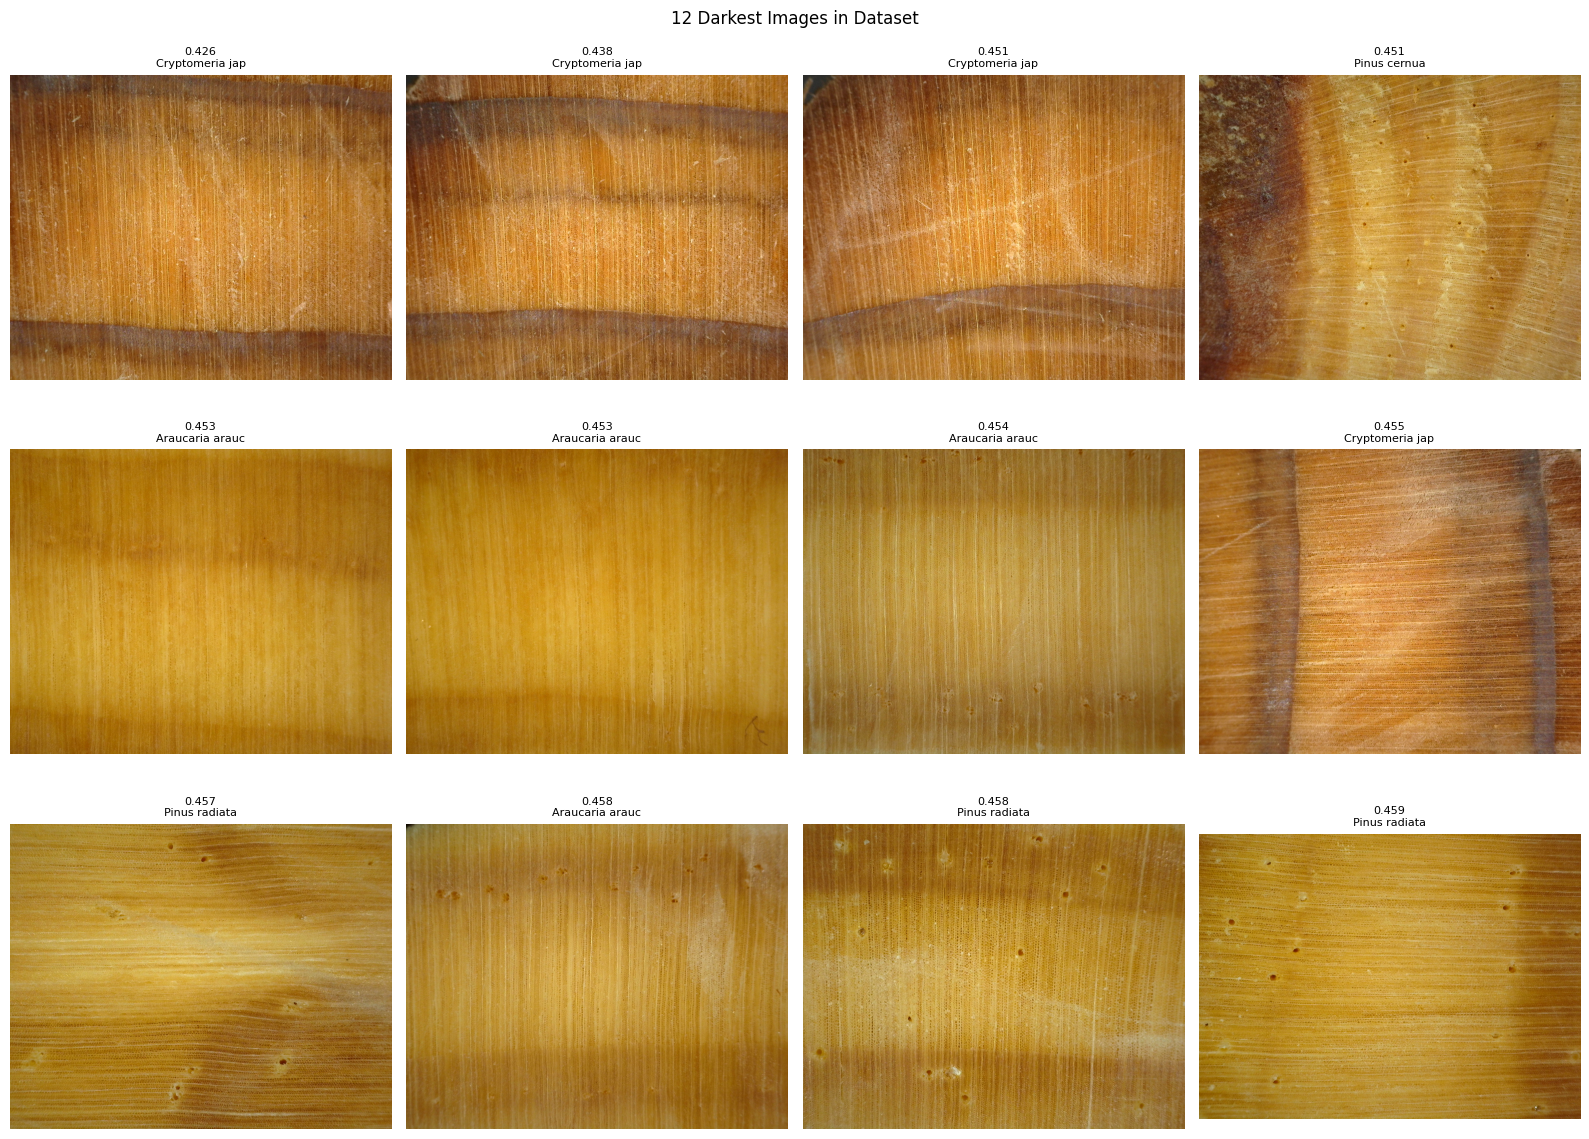

In [8]:
# Show 12 darkest images
darkest = df.nsmallest(12, 'mean')
n = len(darkest)
n_cols = 4
n_rows = (n + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
if n_rows == 1:
    axes = np.array(axes).reshape(1, n_cols)

for idx, (_, row) in enumerate(darkest.iterrows()):
    r, c = idx // n_cols, idx % n_cols
    if n_rows == 1:
        ax = axes[0, c]
    else:
        ax = axes[r, c]
    try:
        img = Image.open(row['path'])
        ax.imshow(img)
        ax.set_title(f"{row['mean']:.3f}\n{row['species'][:15]}", fontsize=8)
    except:
        ax.text(0.5, 0.5, 'Error', ha='center')
    ax.axis('off')

for idx in range(n, n_rows * n_cols):
    r, c = idx // n_cols, idx % n_cols
    if n_rows == 1:
        axes[0, c].axis('off')
    else:
        axes[r, c].axis('off')

plt.suptitle("12 Darkest Images in Dataset")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'darkest_images.png', dpi=150)
plt.show()

## 9. Distribution Visualization

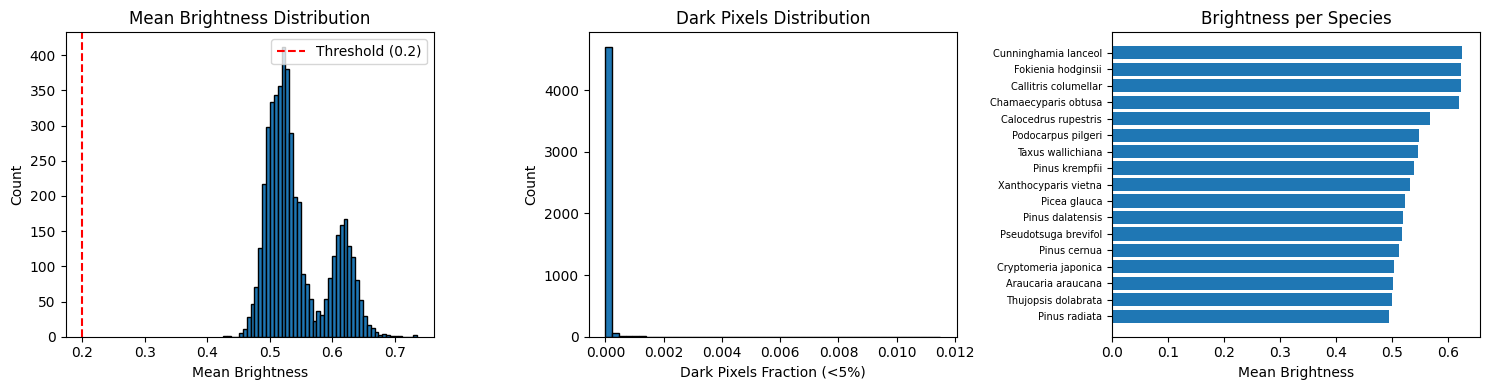

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Mean brightness distribution
axes[0].hist(df['mean'], bins=50, edgecolor='black')
axes[0].set_xlabel('Mean Brightness')
axes[0].set_ylabel('Count')
axes[0].set_title('Mean Brightness Distribution')
axes[0].axvline(x=0.2, color='red', linestyle='--', label='Threshold (0.2)')
axes[0].legend()

# Dark 5pct distribution
axes[1].hist(df['dark_5pct'], bins=50, edgecolor='black')
axes[1].set_xlabel('Dark Pixels Fraction (<5%)')
axes[1].set_ylabel('Count')
axes[1].set_title('Dark Pixels Distribution')

# Per species mean
species_mean_sorted = df.groupby('species')['mean'].mean().sort_values()
axes[2].barh(range(len(species_mean_sorted)), species_mean_sorted.values)
axes[2].set_yticks(range(len(species_mean_sorted)))
axes[2].set_yticklabels([s[:20] for s in species_mean_sorted.index], fontsize=7)
axes[2].set_xlabel('Mean Brightness')
axes[2].set_title('Brightness per Species')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'brightness_distribution.png', dpi=150)
plt.show()

## 10. Check Predictions for Dark Images

In [10]:
# Load predictions
PREDICTIONS_PATH = ROOT / "docs" / "reports" / "experiments" / "phase_1b" / "final_b_new_recomputed" / "20260819T043733Z" / "predictions.csv"

if PREDICTIONS_PATH.exists():
    pred_df = pd.read_csv(PREDICTIONS_PATH)
    
    # Filter ConvNeXt-Tiny seed 42 test
    test_results = pred_df[
        (pred_df['backbone'] == 'convnext_tiny') &
        (pred_df['experiment'] == 'main') &
        (pred_df['seed'] == 42) &
        (pred_df['split'] == 'test')
    ].copy()
    
    print(f"Test set: {len(test_results)} samples")
    
    # Find dark test images
    test_df_copy = df.copy()
    test_df_copy['image_path_relative'] = test_df_copy['path'].apply(
        lambda x: str(Path(x).relative_to(ROOT))
    )
    
    dark_test = test_results.merge(
        test_df_copy[['image_path_relative', 'mean', 'dark_5pct', 'very_dark']],
        left_on='image_path',
        right_on='image_path_relative',
        how='inner'
    )
    
    # Filter to dark ones
    dark_test_flagged = dark_test[dark_test['very_dark'] > 0.01]
    print(f"Test images with dark artifacts: {len(dark_test_flagged)}")
    
    if len(dark_test_flagged) > 0:
        acc = dark_test_flagged['correct'].mean()
        print(f"Accuracy on dark test images: {acc:.4f}")
        print(f"Errors on dark images: {(~dark_test_flagged['correct']).sum()}")
    else:
        print("No dark test images found.")
else:
    print("Predictions file not found")

Test set: 532 samples
Test images with dark artifacts: 0
No dark test images found.


## 11. Conclusions

In [11]:
print("""
============================================================
DARK ARTIFACT CHECK - CONCLUSIONS
============================================================
""")

mean_brightness = df['mean'].mean()
min_brightness = df['mean'].min()
max_dark = df['dark_5pct'].max()
n_dark = len(dark_images)

print(f"Dataset summary:")
print(f"  Total images: {len(df)}")
print(f"  Mean brightness: {mean_brightness:.4f}")
print(f"  Min brightness: {min_brightness:.4f}")
print(f"  Max dark pixel fraction: {max_dark:.4%}")
print(f"  Images with dark artifacts: {n_dark}")

if n_dark == 0 and mean_brightness > 0.3:
    print("\n✓ Dataset is CLEAN - no significant dark artifacts")
    print("  Conclusion: Dark artifact issue is not present in current dataset")
elif n_dark > 0:
    print(f"\n⚠️ Found {n_dark} images with dark artifacts")
    print("  These may need preprocessing before training")

print("\n============================================================")

# Save results
df.to_csv(OUTPUT_DIR / 'image_brightness_analysis.csv', index=False)
if len(dark_images) > 0:
    dark_images.to_csv(OUTPUT_DIR / 'flagged_dark_images.csv', index=False)
print("\nSaved: image_brightness_analysis.csv")


DARK ARTIFACT CHECK - CONCLUSIONS

Dataset summary:
  Total images: 4800
  Mean brightness: 0.5433
  Min brightness: 0.4256
  Max dark pixel fraction: 1.1494%
  Images with dark artifacts: 0

✓ Dataset is CLEAN - no significant dark artifacts
  Conclusion: Dark artifact issue is not present in current dataset


Saved: image_brightness_analysis.csv
